In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pythtb import TBModel, Lattice, Mesh, WFArray
import matplotlib.transforms as mtransforms
from math import pi
from pythtb.visualization import plot_tbmodel


import pythtb
print(pythtb.__version__)

2.0.0


## Funciones

In [2]:
#funcion sin wfa
def stanene_pythtb(Ez, B=[0.05, 0., 0.]):
    # ============================================================
    # PARAMETROS GEOMETRICOS
    # ============================================================

    a = 4.6756          # Angstrom, constante de red del honeycomb
    Dz = 0.86           # Angstrom, buckling (referencia geometrica)
    theta = 107.1*pi/180

    # Distancia entre primeros vecinos
    a_nn = a/np.sqrt(3)

    # Parametro onsite p-s, ajustado a DFT
    xi0 = 0.644         # eV


    # ============================================================
    # VECTORES A PRIMEROS VECINOS
    # ============================================================
    # theta = angulo respecto del eje +z
    #
    # d1 = a_nn (sin(theta), 0, cos(theta))
    # d2 = a_nn (-sin(theta)/2, sqrt(3) sin(theta)/2, cos(theta))
    # d3 = a_nn (-sin(theta)/2,-sqrt(3) sin(theta)/2, cos(theta))
    #
    # Con theta > 90°, cos(theta)<0

    d1 = a_nn * np.array([np.sin(theta),    0,  np.cos(theta)])

    d2 = a_nn * np.array([-0.5*np.sin(theta),    np.sqrt(3)/2*np.sin(theta),    np.cos(theta)])

    d3 = a_nn * np.array([-0.5*np.sin(theta),    -np.sqrt(3)/2*np.sin(theta),    np.cos(theta)])


    # ============================================================
    # COSENOS DIRECTORES
    # ============================================================

    def direction_cosines(d):
        """Devuelve (l,m,n) para el vector de enlace d."""
        norm = np.linalg.norm(d)
        return d[0]/norm, d[1]/norm, d[2]/norm


    (l1, m1, n1) = direction_cosines(d1)
    (l2, m2, n2) = direction_cosines(d2)
    (l3, m3, n3) = direction_cosines(d3)


    # ============================================================
    # PARAMETROS DE SLATER-KOSTER
    # ============================================================

    VssS = -2.6245       # <s|H|s> sigma, eV
    VspS =  2.6504       # <s|H|p> sigma, eV
    VppS =  1.4926       # <p|H|p> sigma, eV
    VppP = -0.7877       # <p|H|p> pi,    eV


    # ============================================================
    # MATRIZ DE HOPPING SLATER-KOSTER
    #
    # Base:
    #       | s, px, py, pz >
    #
    # T_j[mu,nu] =
    # < mu, A | H | nu, B_j >
    #
    # para el enlace A -> B_j.
    # ============================================================

    def hopping_SK(l, m, n):
        """
        Matriz 4x4 de Slater-Koster para un enlace cuya dirección
        tiene cosenos directores (l,m,n).

        Base: [s, px, py, pz]

        Convención usada:
            <s|p_alpha> = direction_cosine * VspS
            <p_alpha|s> = -direction_cosine * VspS

        Los elementos p-p siguen la tabla estándar SK.
        """

        T = np.zeros((4, 4), dtype=float)

        # --------------------------------------------------------
        # s-s
        # --------------------------------------------------------

        T[0, 0] = VssS


        # --------------------------------------------------------
        # s-p
        # --------------------------------------------------------
        # <s|px>, <s|py>, <s|pz>

        T[0, 1] =  l * VspS
        T[0, 2] =  m * VspS
        T[0, 3] =  n * VspS


        # --------------------------------------------------------
        # p-s
        # --------------------------------------------------------
        # Debido a la paridad del orbital p:
        #
        # <px|s> = -l VspS
        # <py|s> = -m VspS
        # <pz|s> = -n VspS

        T[1, 0] = -l * VspS
        T[2, 0] = -m * VspS
        T[3, 0] = -n * VspS


        # --------------------------------------------------------
        # p-p
        # --------------------------------------------------------

        # diagonal
        T[1, 1] = l*l * VppS + (1-l*l) * VppP
        T[2, 2] = m*m * VppS + (1-m*m) * VppP
        T[3, 3] = n*n * VppS + (1-n*n) * VppP

        # fuera de diagonal
        T[1, 2] = l*m * (VppS - VppP)
        T[2, 1] = T[1, 2]

        T[1, 3] = l*n * (VppS - VppP)
        T[3, 1] = T[1, 3]

        T[2, 3] = m*n * (VppS - VppP)
        T[3, 2] = T[2, 3]


        return T


    # ============================================================
    # MATRICES DE HOPPING PARA LOS TRES PRIMEROS VECINOS
    # ============================================================

    T1 = hopping_SK(l1, m1, n1)
    T2 = hopping_SK(l2, m2, n2)
    T3 = hopping_SK(l3, m3, n3)



    # --------------------------------------------------------
    # VECTORES PRIMITIVOS
    # --------------------------------------------------------

    # Honeycomb:
    #
    # a1 = a (1,0)
    # a2 = a (1/2,sqrt(3)/2)

    lat_vecs = [
        [a, 0.0],
        [a/2.0, a*np.sqrt(3.0)/2.0]
    ]


    # --------------------------------------------------------
    # POSICIONES DE LOS ORBITALES
    # --------------------------------------------------------

    # A se toma como origen.
    #
    # B se encuentra desplazado respecto de A por la
    # proyección in-plane de uno de los primeros vecinos.
    #
    # Para el modelo de Hattori podemos tomar como referencia
    # el primer enlace A -> B.

    orb_vecs = [
        [0.0, 0.0],   # A,s
        [0.0, 0.0],   # A,px
        [0.0, 0.0],   # A,py
        [0.0, 0.0],   # A,pz

        [1./3., 1./3.],     # B,s
        [1./3., 1./3.],     # B,px
        [1./3., 1./3.],     # B,py
        [1./3., 1./3.],     # B,pz
    ]


    # --------------------------------------------------------
    # LATTICE
    # --------------------------------------------------------

    lat = Lattice(
        lat_vecs=lat_vecs,
        orb_vecs=orb_vecs,
        periodic_dirs=[0,1]
    )

    model = TBModel(
        lattice=lat,
        spinful=True
    )

    sx=np.array([0.,1.,0.,0])
    sy=np.array([0.,0.,1.,0])
    sz=np.array([0.,0.,0.,1])

    # ========================================================
    # ON-SITE ENERGIES
    # ========================================================

    eps_s = -9.00
    eps_p = -3.39

    # Campo eléctrico:
    #
    # V = Ez * z / 2
    #
    # A -> +V
    # B -> -V

    V = Ez * Dz / 2.0
    #Ajuta nivel de Fermi a 0

    # FL=-3.7113856547660458
    FL=-3.721
    onsite_A = [
        eps_s + V-FL,
        eps_p + V-FL,
        eps_p + V-FL,
        eps_p + V-FL
    ]

    onsite_B = [
        eps_s - V-FL,
        eps_p - V-FL,
        eps_p - V-FL,
        eps_p - V-FL
    ]

    magnetic= [
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz]), 
        np.dot(B, [sx, sy, sz])
    ]

    model.set_onsite(onsite_A + onsite_B, mode='add')

    model.set_onsite(magnetic, mode='add')

    # ========================================================
    # MATRICES DE IDENTIDAD EN SPIN
    # ========================================================

    sigma0 = np.eye(2, dtype=complex)


    # ========================================================
    # HOPPING DE PRIMEROS VECINOS
    # ========================================================

    # Cada Tj es una matriz 4x4 orbital.
    #
    # Para cada hopping orbital -> orbital:
    #
    # amplitud = t_{alpha,beta} * I_spin
    #
    # PythTB genera automáticamente el conjugado hermítico.

    T_list = [T1, T2, T3]


    # --------------------------------------------------------
    # VECTORES DE CELDA PARA LOS TRES VECINOS
    # --------------------------------------------------------

    # El vecino 1 está en la celda [0,0].
    #
    # Los otros dos se encuentran en las celdas vecinas
    # correspondientes.

    neighbor_cells = [
        [0, 0],
        [-1, 0],
        [0, -1]
    ]


    # --------------------------------------------------------
    # Hoppings A -> B
    # --------------------------------------------------------

    for T, R in zip(T_list, neighbor_cells):

        for alpha in range(4):

            for beta in range(4):

                amp = T[alpha, beta] * sigma0

                model.set_hop(amp,  alpha,  4 + beta,   ind_R=R)    #hopping de A a B requiere pasar por las 4 bases del medio


    # ========================================================
    # SPIN-ORBIT COUPLING
    # ========================================================

    # --------------------------------------------------------
    # SOC entre orbitales p
    # --------------------------------------------------------

    # H_SO = xi0/2 * epsilon_{alpha beta gamma}
    #        (-i sigma_gamma) + H.c.
    #
    # Las parejas relevantes son:
    #
   
    # A sublattice
    model.set_hop(-1j * xi0/2.0 * sz,   1, 2,   ind_R=[0,0],    mode="add")     # px <-> py  mediante sigma_z

    model.set_hop(-1j * xi0/2.0 * sx,   2, 3,   ind_R=[0,0],    mode="add")     # py <-> pz  mediante sigma_x

    model.set_hop(-1j * xi0/2.0 * sy,   3, 1,   ind_R=[0,0],    mode="add")     # pz <-> px  mediante sigma_y


    # B sublattice
    model.set_hop(-1j * xi0/2.0 * sz,   5, 6,   ind_R=[0,0],    mode="add")     # px <-> py  mediante sigma_z

    model.set_hop(-1j * xi0/2.0 * sx,   6, 7,   ind_R=[0,0],    mode="add")     # py <-> pz  mediante sigma_x

    model.set_hop(-1j * xi0/2.0 * sy,   7, 5,   ind_R=[0,0],    mode="add")     # pz <-> px  mediante sigma_y


    return model

In [3]:

def gap_2d(model, mallado=240):
    n_occ = model.norb

    ks = np.linspace(-0.5, 0.5, mallado, endpoint=False)   #con endpoint false, el mallado tiene que ser multiplo de 6 para contener a K
    k_pts = [[kx, ky] for kx in ks for ky in ks]

    evals = model.solve_ham(k_pts=k_pts)  # (Nk=mallado**2, 16)

    val = evals[:, n_occ - 1]
    cond = evals[:, n_occ]

    return np.min(cond)-np.max(val)     #gap indirecto si es necesario

def gap_1d(model, mallado=240):
    n_occ = model.norb

    k_vals = np.linspace(0, 1, mallado, endpoint=False)
    k_pts = [[k] for k in k_vals]

    evals = model.solve_ham(k_pts=k_pts)  # (mallado, 16)
    gap=np.min(evals[:, n_occ]) - np.max(evals[:, n_occ - 1])           #gap indirecto es el más adecuado para este análisis
    if gap<0:
        return 0
    return gap

# def gap_1d_gamma(model):
#     n_occ = model.norb

#     k=0

#     evals = model.solve_ham(k_pts=k)  # (1, 16)
#     gap=evals[n_occ] - evals[n_occ - 1]
#     if gap<0:
#         return 0
#     return gap

def plot_gap_2d(km_model, mallado=300):
    # grilla centrada en Gamma, en coordenadas reducidas de pythtb
    ks = np.linspace(-0.5, 0.5, mallado, endpoint=False)

    gap = np.zeros((mallado, mallado))

    for ix, kx in enumerate(ks):
        for iy, ky in enumerate(ks):
            evals = np.sort(km_model.solve_ham([kx, ky]))
            gap[iy, ix] = evals[8] - evals[7]   # 4 bandas -> gap de mitad de llenado

    
    def do_plot(ax, Z, transform):
        im = ax.imshow(Z, interpolation='none',
                       origin='lower',
                       extent=[-pi, pi, -pi, pi], vmin=0, clip_on=True)

        trans_data = transform + ax.transData
        im.set_transform(trans_data)

        # display intended extent of the image
        x1, x2, y1, y2 = im.get_extent()
        pcm = ax.plot([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], "y--",
                transform=trans_data)
        ax.set_xlim(-5,5)
        ax.set_ylim(-5,5)
        return im
    fig, ax = plt.subplots(1,1)
    im = do_plot(ax, gap, mtransforms.Affine2D().skew_deg(-15, -15))
    fig.colorbar(im, ax=ax)
    plt.show()
    print(np.min(gap))    
    return gap


In [4]:
#curvas teoricas del gapless
def theoric_curves(E_plot):

    #parametro aprox donde se cierra el gap para B=0
    E_c=46./450.

    #parametro fitteado con E=0.4 cuando B=0.15
    A=0.15**2/(0.4**2-E_c**2)

    B1 = np.sqrt(A*(E_plot**2 - E_c**2))
    plt.plot(E_plot, B1, 'r--', label=r"$E^2 - B^2/A = C^2$",linewidth=0.5)

    # #curva B=aE
    # B2= E_plot*np.sqrt(A)
    # plt.plot(E_plot, B2, 'w-', label=r"$B=aE$", linewidth=0.5)
    # plt.legend()


## Mapa de Gaps 1D y 2D

In [5]:
mesh = 50

B_min = 0
B_max = 1
E_min = 0
E_max = 0.6

calcula

In [6]:
from joblib import Parallel, delayed
import numpy as np


def compute_point(i, j, B, e):
    
    model = stanene_pythtb(e, B=[B, 0, 0])
    gap2d = gap_2d(model)

    fin_model_1d = model.make_finite(
        periodic_dirs=[0],
        num_cells=[35],
        glue_edges=[False]
    )
    gap1d = gap_1d(fin_model_1d)
    # gap1dgamma= gap_1d_gamma(fin_model_1d)

    return i, j, gap2d, gap1d

In [ ]:
E_vals = np.linspace(E_min, E_max, mesh)
B_vals = np.linspace(B_min, B_max, mesh)

gap_map2D = np.zeros((mesh, mesh))
gap_map1D = np.zeros((mesh, mesh))
# gap_map1D_gamma = np.zeros((mesh, mesh))

tasks = [
    (i, j, B, e)
    for i, B in enumerate(B_vals)
    for j, e in enumerate(E_vals)
]

results = Parallel(n_jobs=-1, verbose=10)(
    delayed(compute_point)(i, j, B, e)
    for i, j, B, e in tasks
)

for i, j, gap2d, gap1d in results:
    gap_map2D[i, j] = gap2d
    gap_map1D[i, j] = gap1d
    # gap_map1D_gamma[i, j] = gap1dgamma


guardado

In [ ]:
np.save("gap_map1D.npy", gap_map1D)
# np.save("gap_map1D_gamma.npy", gap_map1D_gamma)
np.save("gap_map2D.npy", gap_map2D)


In [ ]:
np.save("B_vals.npy", B_vals)
np.save("E_vals.npy", E_vals)

ploteo

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18472\3015828311.py:10: RuntimeWarning: invalid value encountered in sqrt
  B1 = np.sqrt(A*(E_plot**2 - E_c**2))


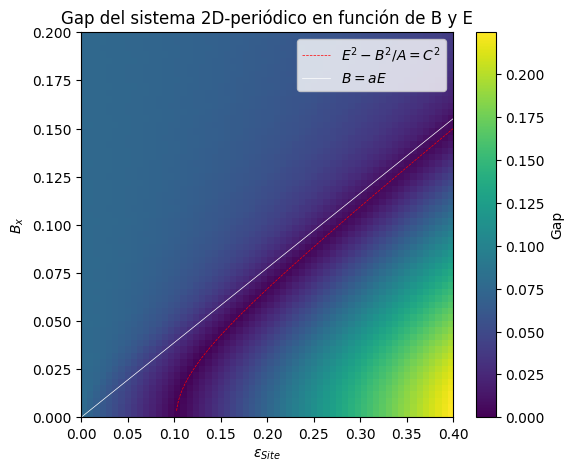

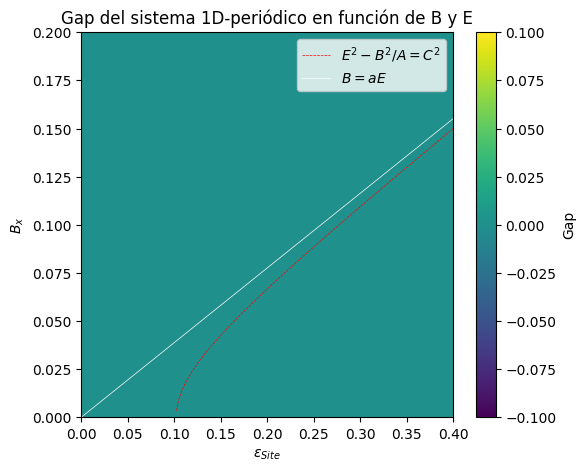

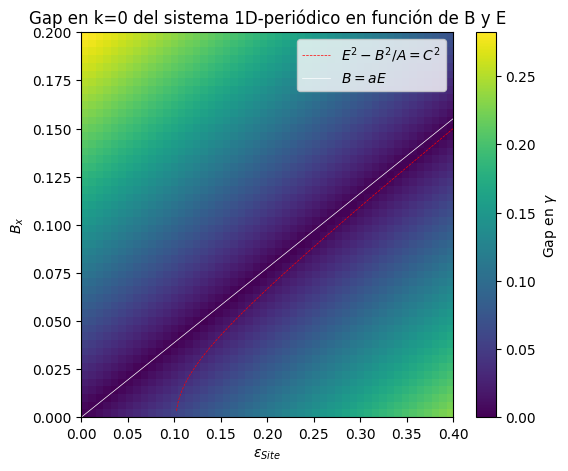

In [ ]:
gap_map1D_gamma = np.load("gap_map1D_gamma.npy")
gap_map1D = np.load("gap_map1D.npy")
gap_map2D = np.load("gap_map2D.npy")
B_vals = np.load("B_vals.npy")
E_vals = np.load("E_vals.npy")

# '''-----------------------------------2D----------------------------------'''
plt.figure(figsize=(6,5))
plt.imshow(
    gap_map2D,
    origin="lower",
    aspect="auto",
    vmin=0,
    extent=[E_vals[0], E_vals[-1], B_vals[0], B_vals[-1]]
)
plt.colorbar(label="Gap")
plt.xlabel(r"$\epsilon_{Site}$")
plt.ylabel(r"$B_x$")
plt.title("Gap del sistema 2D-periódico en función de B y E")

E_plot = np.linspace(E_vals[0], E_vals[-1], 500)
theoric_curves(E_plot)
plt.ylim(top=B_max)

plt.show()
'''-----------------------------------1D----------------------------------'''
plt.figure(figsize=(6,5))
plt.imshow(
    gap_map1D,
    origin="lower",
    aspect="auto",
    vmin=0,
    extent=[E_vals[0], E_vals[-1], B_vals[0], B_vals[-1]]
)
plt.colorbar(label="Gap")
plt.xlabel(r"$\epsilon_{Site}$")
plt.ylabel(r"$B_x$")
plt.title("Gap del sistema 1D-periódico en función de B y E")

E_plot = np.linspace(E_vals[0], E_vals[-1], 500)
theoric_curves(E_plot)
plt.ylim(top=B_max)

plt.show()

# '''-----------------------------------1D gamma----------------------------------'''
# plt.figure(figsize=(6,5))
# plt.imshow(
#     gap_map1D_gamma,
#     origin="lower",
#     aspect="auto",
#     vmin=0,
#     extent=[E_vals[0], E_vals[-1], B_vals[0], B_vals[-1]]
# )
# plt.colorbar(label=r"Gap en $\gamma$")
# plt.xlabel(r"$\epsilon_{Site}$")
# plt.ylabel(r"$B_x$")
# plt.title("Gap en k=0 del sistema 1D-periódico en función de B y E")

# E_plot = np.linspace(E_vals[0], E_vals[-1], 500)
# theoric_curves(E_plot)
# plt.ylim(top=B_max)

# plt.show()


Sigue habiendo un comportamiento hiperbólico en el límite entre fase topológica y trivial, como en el Kane-Mele.

El 1D siempre tiene el gap indirecto cerrado, por lo que es semimetal siempre y los estados de borde están presentes incluso por fuera de la fase topológica.

En el punto gamma parece que se cierra el gap solo en un punto para cada B. Y ese límite es lineal con E, pero no es V=B como en el KM. Aún así sigue siendo igual a la asíntota oblicua a la que tiende la curva hiperbólica del cierre de gap 2D, como sí pasaba en KM. Por lo que probablemente sirva también como un límite para la posible aparición de estado de corner.